<a href="https://colab.research.google.com/github/alla-malts-ds/data-visualization-practice/blob/main/%22HW_11_2_%D0%92%D1%96%D0%B7%D1%83%D0%B0%D0%BB%D1%96%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%B4%D0%B0%D0%BD%D0%B8%D1%85_%D0%B7_Matplotlib_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Візуалізація даних з Matplotlib

## Опис завдання
У цьому домашньому завданні ви продовжите працювати з датасетом про оренду велосипедів `yulu_rental.csv`, але тепер будете використовувати бібліотеку Matplotlib для створення більш складних та налаштованих візуалізацій.

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - відчувається як температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів

## Підготовка даних

---


🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.

Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# Завантаження даних
df = pd.read_csv('/content/drive/MyDrive/Data_Loves_Academy/Module 11/yulu_rental.csv')

In [3]:
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Додаткові колонки
df['month'] = df.index.month
df['hour'] = df.index.hour
df['weekday'] = df.index.day_name()
df['weekday_num'] = df.index.weekday
df['week'] = df.index.isocalendar().week
df['year'] = df.index.year
df['day'] = df.index.day

## Завдання 1: Порівняння Pandas vs Matplotlib

**Завдання:**
Побудуйте лінійний графік середньої кількості оренд помісячно впродовж всього періоду в даних двома способами:
1. Використовуючи Pandas (DataFrame.plot())
2. Використовуючи Matplotlib безпосередньо

В обох методах додайте маркери-кружечки. Можна також задати свій відмінний від стандартного колір.

Підказка: отримати потрібний формат даних найзручніше з методом датафрейму `resample`.

**Опишіть свої спостереження:** чим відрізняються 2 побудованих графіки? Який вам більше подобається?

In [4]:
monthly_avg = df['count'].resample('MS').mean()
monthly_avg.head(5)

,count
datetime,
2011-01-01,54.645012
2011-02-01,73.641256
2011-03-01,86.849776
2011-04-01,111.026374
2011-05-01,174.809211


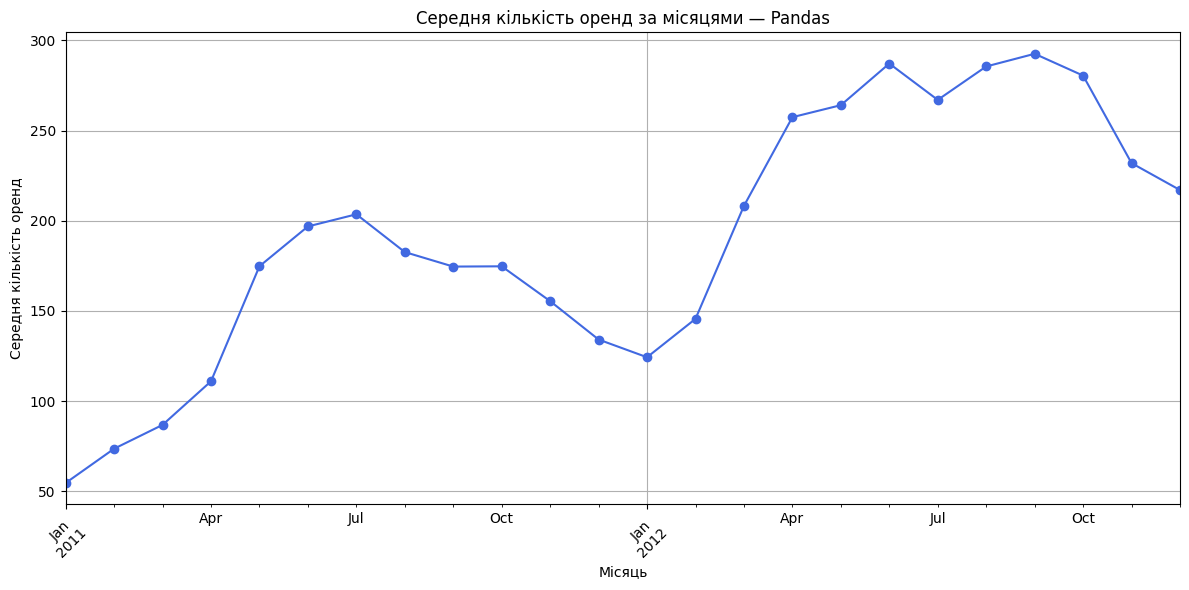

In [5]:
# Побудова лінійного графіка за допомогою Pandas
monthly_avg.plot(
    marker='o',
    color='royalblue',
    figsize=(12, 6),
    title='Середня кількість оренд за місяцями — Pandas',
    xlabel='Місяць',
    ylabel='Середня кількість оренд',
    grid=True
)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

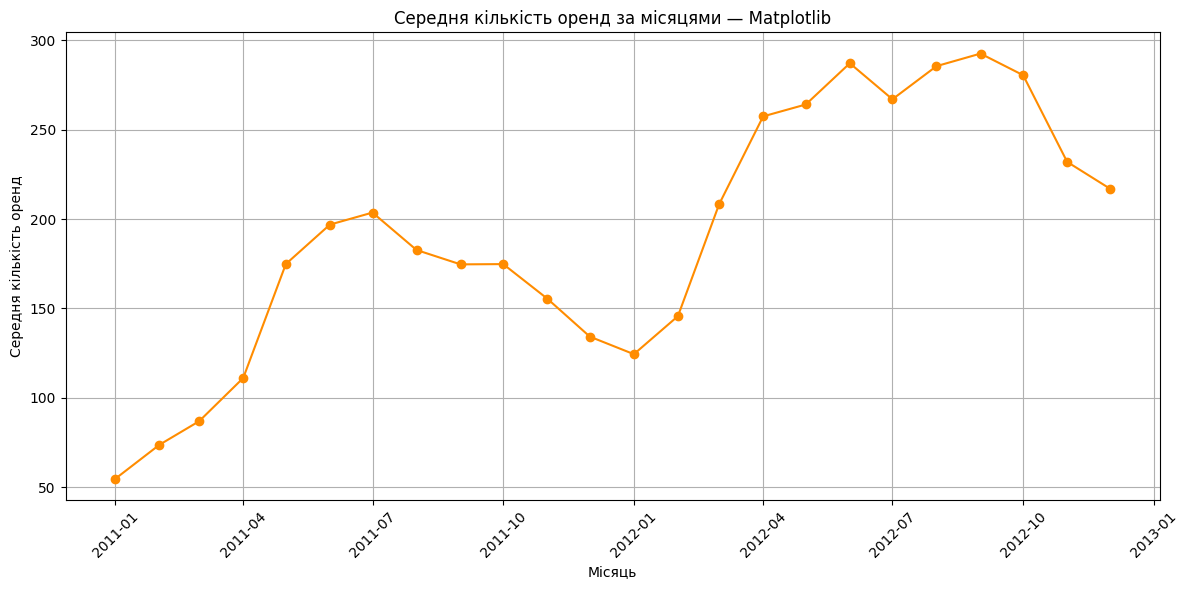

In [6]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_avg.index,
    monthly_avg.values,
    marker='o',
    linestyle='-',
    color='darkorange'
)

plt.title('Середня кількість оренд за місяцями — Matplotlib')
plt.xlabel('Місяць')
plt.ylabel('Середня кількість оренд')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Графіки відрізняються переважно способом побудови й оформленням. У Pandas метод .plot() викликається безпосередньо для об’єкта Series, а основні параметри передаються всередині методу, тому код виходить коротшим. У Matplotlib полотно, лінія, заголовок, підписи осей і сітка додаються окремими командами. Це потребує більше коду, але дає більше контролю над кожним елементом графіка. На побудованих графіках також відрізняються колір лінії, формат і частота відображення дат на осі X.

Мені більше подобається графік, створений за допомогою Matplotlib, тому що підписи дат на осі X відображаються детальніше й графік легше читати. Крім того, Matplotlib дозволяє точніше налаштувати всі елементи візуалізації.

## Завдання 2: Робота зі списками та numpy

**Завдання:**
Вам задані 3 списки:
1. Номер дня тижня.
2. Продажі в тиждень 1.
3. Продажі в тиждень 2.

Створіть графік, на якому лінійними графіками різних кольорів накладено продажі за обидва тижні.

Обовʼязково додайте назву графіку, підписи вісям ОХ, ОУ, назви кожного з рядів даних, легенду.

**Дайте відповіді на питання**
1. Судячи з графіку, в який тиждень проодажі були стабільніше?
2. Чи можете ви підкріпити свій висновок обчисленнями? Якими саме? Можна (але не обовʼязково) навести ці обчислення.

In [7]:
# Дані у вигляді списків
days = [1, 2, 3, 4, 5, 6, 7] # 1 - це понеділок
sales_week1 = [1349,1562,1600,1606,1510,959,822]  # Продажі за тиждень1
sales_week2 = [1321,1263,1162,1406,1421,1248,1204]  # Продажі за тиждень1

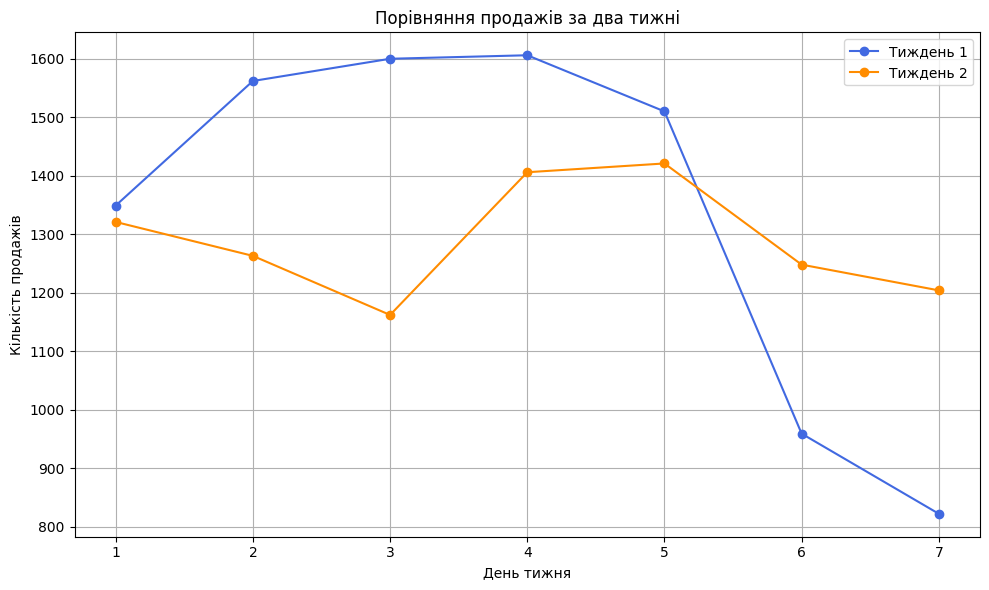

In [8]:
plt.figure(figsize=(10, 6))

plt.plot(
    days,
    sales_week1,
    marker='o',
    color='royalblue',
    label='Тиждень 1'
)

plt.plot(
    days,
    sales_week2,
    marker='o',
    color='darkorange',
    label='Тиждень 2'
)

plt.title('Порівняння продажів за два тижні')
plt.xlabel('День тижня')
plt.ylabel('Кількість продажів')

plt.xticks(days)

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
std_week1 = np.std(sales_week1)
std_week2 = np.std(sales_week2)

range_week1 = np.max(sales_week1) - np.min(sales_week1)
range_week2 = np.max(sales_week2) - np.min(sales_week2)

print('Стандартне відхилення за тиждень 1:', round(std_week1, 2))
print('Стандартне відхилення за тиждень 2:', round(std_week2, 2))

print('Розмах продажів за тиждень 1:', range_week1)
print('Розмах продажів за тиждень 2:', range_week2)

Стандартне відхилення за тиждень 1: 300.0
Стандартне відхилення за тиждень 2: 90.91
Розмах продажів за тиждень 1: 784
Розмах продажів за тиждень 2: 259


Судячи з графіка, у другий тиждень продажі були стабільнішими. Значення продажів другого тижня коливаються в порівняно вузькому діапазоні, тоді як у перший тиждень після зростання до 1606 продажів спостерігається різке падіння до 822.

Висновок можна підтвердити за допомогою стандартного відхилення та розмаху. Стандартне відхилення за перший тиждень становить приблизно 300, а за другий тиждень приблизно 90,91. Розмах продажів у перший тиждень дорівнює 784, а в другий 259. Обидва показники значно менші для другого тижня, тому продажі другого тижня були стабільнішими.

## Завдання 3: Subplot - 2x2 сітка графіків

**Завдання:**
Створіть сітку 2x2 з чотирма різними графіками, використовуючи `plt.subplot()`:
1. Лінійний графік середньої температури помісячно.
2. Стовпчикова діаграма середньої годинної кількості оренд за кварталами.
3. Гістограма вологості за всіма погодинними вимірами.
4. Scatter plot температури vs кількості оренд.

Кожен підграфік має містити всі необхідні підписи. Дашборд має містити назву.

In [11]:
monthly_temp = df['temp'].resample('MS').mean()

quarterly_rentals = df.groupby('season')['count'].mean()
quarterly_rentals.index = ['Q1', 'Q2', 'Q3', 'Q4']

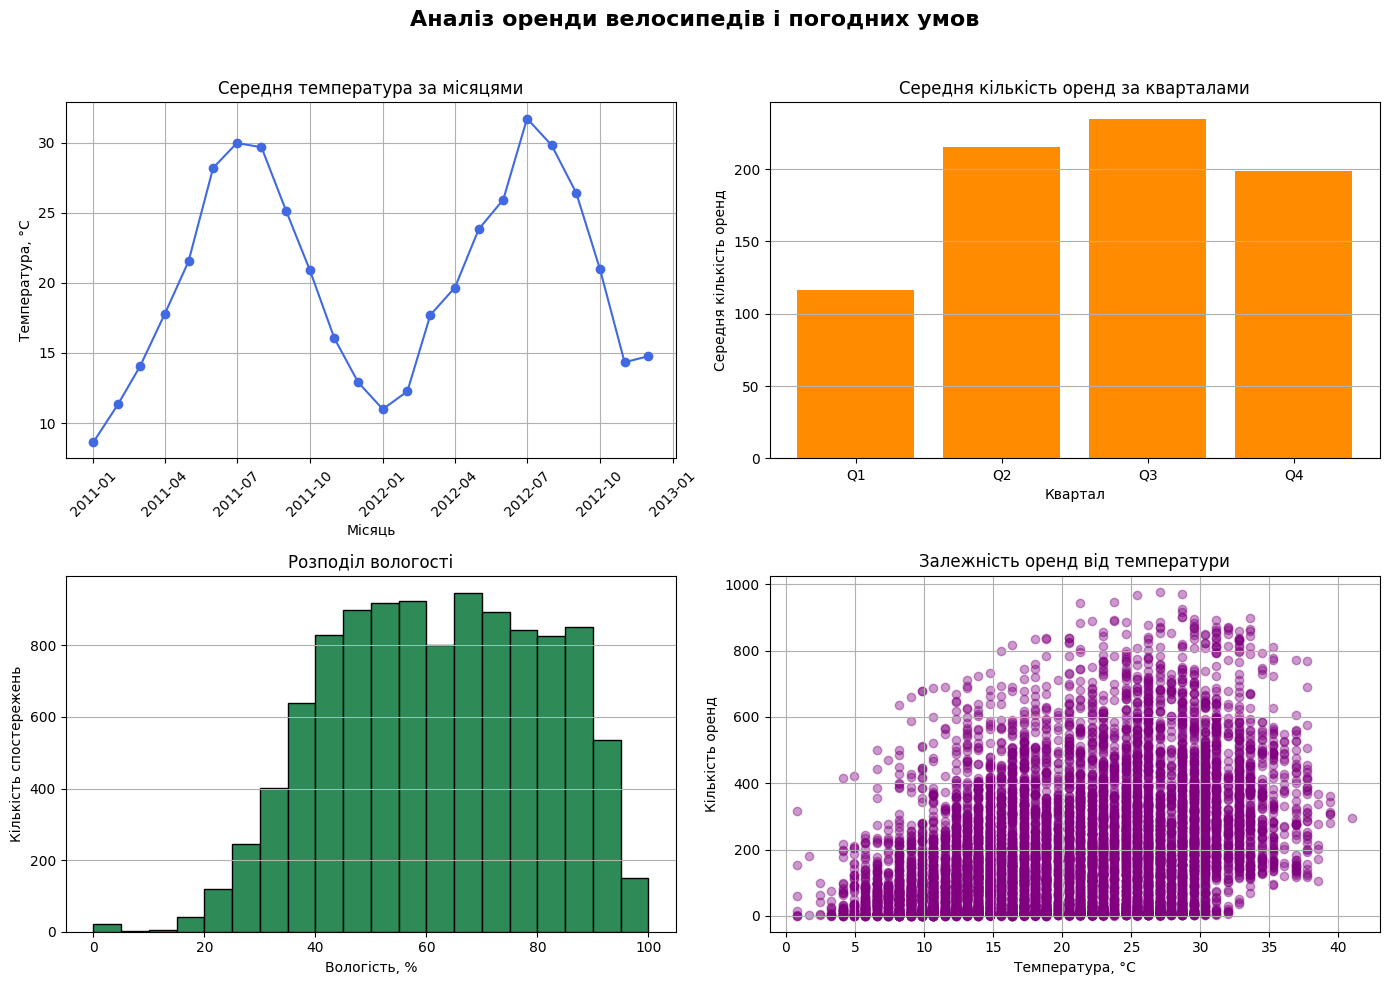

In [14]:
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.plot(
    monthly_temp.index,
    monthly_temp.values,
    marker='o',
    color='royalblue'
)
plt.title('Середня температура за місяцями')
plt.xlabel('Місяць')
plt.ylabel('Температура, °C')
plt.xticks(rotation=45)
plt.grid(True)

plt.subplot(2, 2, 2)
plt.bar(
    quarterly_rentals.index,
    quarterly_rentals.values,
    color='darkorange'
)
plt.title('Середня кількість оренд за кварталами')
plt.xlabel('Квартал')
plt.ylabel('Середня кількість оренд')
plt.grid(axis='y')

plt.subplot(2, 2, 3)
plt.hist(
    df['humidity'],
    bins=20,
    color='seagreen',
    edgecolor='black'
)
plt.title('Розподіл вологості')
plt.xlabel('Вологість, %')
plt.ylabel('Кількість спостережень')
plt.grid(axis='y')

plt.subplot(2, 2, 4)
plt.scatter(
    df['temp'],
    df['count'],
    color='purple',
    alpha=0.4
)
plt.title('Залежність оренд від температури')
plt.xlabel('Температура, °C')
plt.ylabel('Кількість оренд')
plt.grid(True)

plt.suptitle(
    'Аналіз оренди велосипедів і погодних умов',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


## Завдання 4: Subplots - об'єктно-орієнтований підхід

**Завдання:**
Створіть той самий набір графіків, але використовуючи `fig, ax = plt.subplots()`.

**Дайте відповідь на питання своїми словами**
- Чим відрізняється підхід побудови кількох графіків на одній фігурі з `plt.subplots()` від `plt.subplot()`?

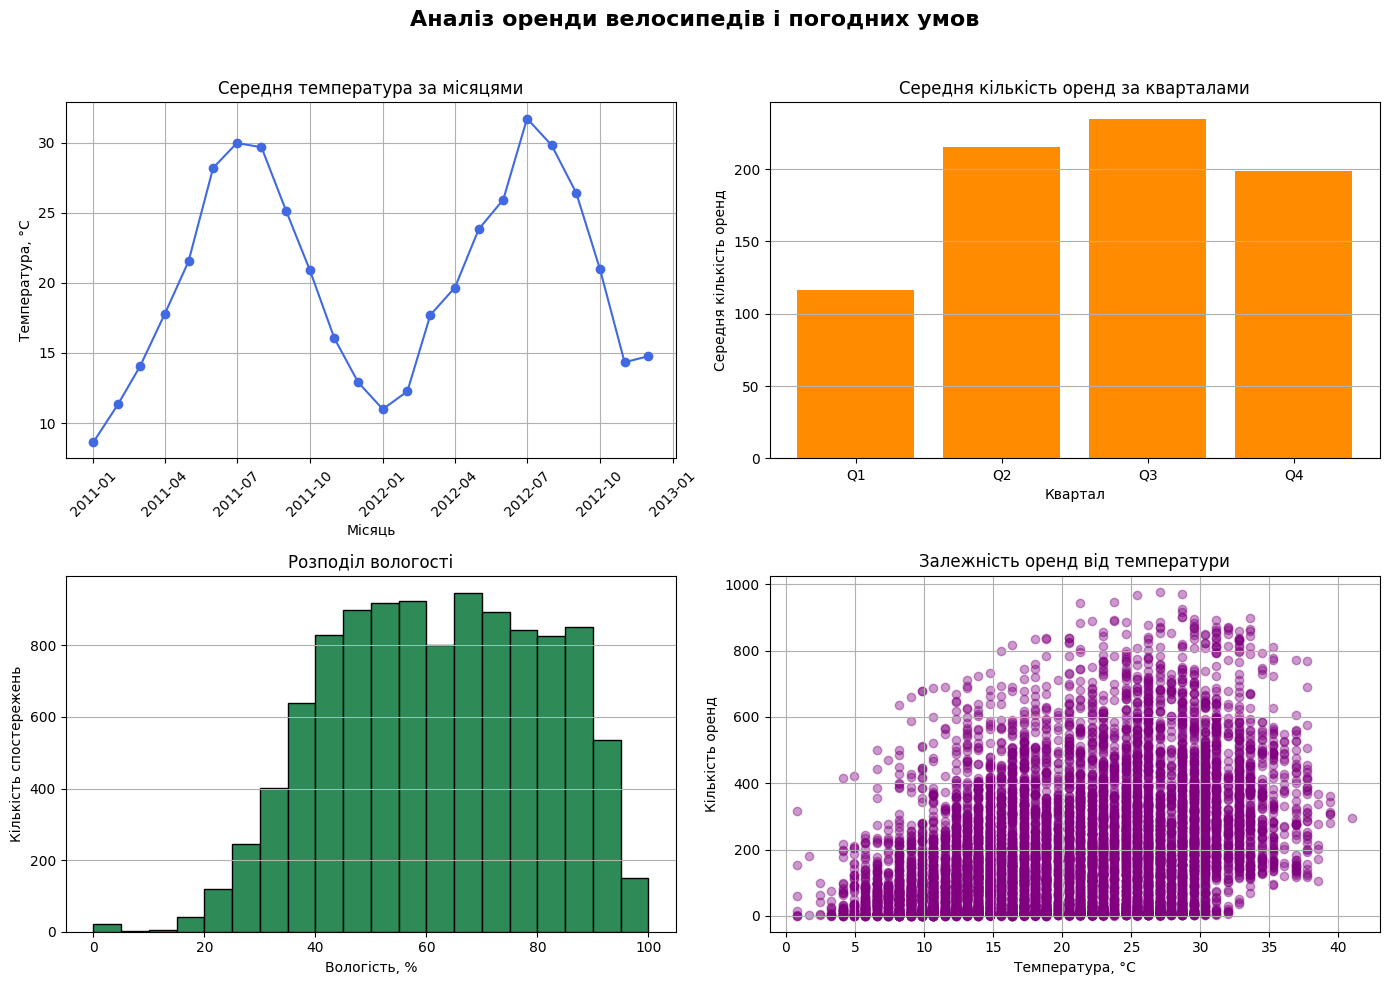

In [13]:
monthly_temp = df['temp'].resample('MS').mean()

quarterly_rentals = df.groupby('season')['count'].mean()
quarterly_rentals.index = ['Q1', 'Q2', 'Q3', 'Q4']

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

ax[0, 0].plot(
    monthly_temp.index,
    monthly_temp.values,
    marker='o',
    color='royalblue'
)
ax[0, 0].set_title('Середня температура за місяцями')
ax[0, 0].set_xlabel('Місяць')
ax[0, 0].set_ylabel('Температура, °C')
ax[0, 0].tick_params(axis='x', rotation=45)
ax[0, 0].grid(True)

ax[0, 1].bar(
    quarterly_rentals.index,
    quarterly_rentals.values,
    color='darkorange'
)
ax[0, 1].set_title('Середня кількість оренд за кварталами')
ax[0, 1].set_xlabel('Квартал')
ax[0, 1].set_ylabel('Середня кількість оренд')
ax[0, 1].grid(axis='y')

ax[1, 0].hist(
    df['humidity'],
    bins=20,
    color='seagreen',
    edgecolor='black'
)
ax[1, 0].set_title('Розподіл вологості')
ax[1, 0].set_xlabel('Вологість, %')
ax[1, 0].set_ylabel('Кількість спостережень')
ax[1, 0].grid(axis='y')

ax[1, 1].scatter(
    df['temp'],
    df['count'],
    color='purple',
    alpha=0.4
)
ax[1, 1].set_title('Залежність оренд від температури')
ax[1, 1].set_xlabel('Температура, °C')
ax[1, 1].set_ylabel('Кількість оренд')
ax[1, 1].grid(True)

fig.suptitle(
    'Аналіз оренди велосипедів і погодних умов',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

Підхід plt.subplot() послідовно активує одну ділянку сітки, після чого всі команди plt.plot(), plt.title(), plt.xlabel() та інші застосовуються до поточного графіка. Потрібно стежити за тим, яка позиція зараз активна.

Метод plt.subplots() одразу створює фігуру fig і масив координатних областей ax. До кожного графіка можна звертатися прямо, наприклад ax[0, 0] або ax[1, 1]. Об’єктно-орієнтований підхід зручніший для складних візуалізацій, оскільки графіки не залежать від поточного активного стану, а код має чіткішу структуру.

## (Опціонально) Завдання 5: Тонкі налаштування форматування графіка

**Завдання:**
Подібно до прикладу, наведеного в лекції, створіть професійно оформлений графік помісячної динаміки оренди з максимальною кількістю деталей та налаштувань. Ваш графік має включати:

**Обов'язкові елементи:**
1. **Три лінії:** середнє, максимум, мінімум за місяцями
2. **Різні стилі ліній:** суцільна, пунктирна, крапкова + різні маркери
3. **Заливка області** між мінімумом та максимумом
4. **Дві анотації:** для найвищого та найнижчого середнього значення
5. **Горизонтальна лінія** середнього за весь рік
6. **Двошарова сітка:** основна та допоміжна
7. **Стилізована легенда** з тінню
8. **Текстовий блок** зі статистикою в кутку графіка
9. **Професійне оформлення:** заголовки, підписи осей з жирним шрифтом

**Результат:** Графік повинен виглядати як готова ілюстрація для бізнес-звіту або наукової публікації.

Приклад очікуваного результату.
![](https://drive.google.com/uc?id=1YoJByivzlqncEF2zbWu3EhGSZ7XRme8T)


**Питання для інтерпретації:**
1. Яка перевага додавання анотацій на графік?
2. Для чого використовується fill_between()?
3. Як текстовий блок допомагає в інтерпретації даних?

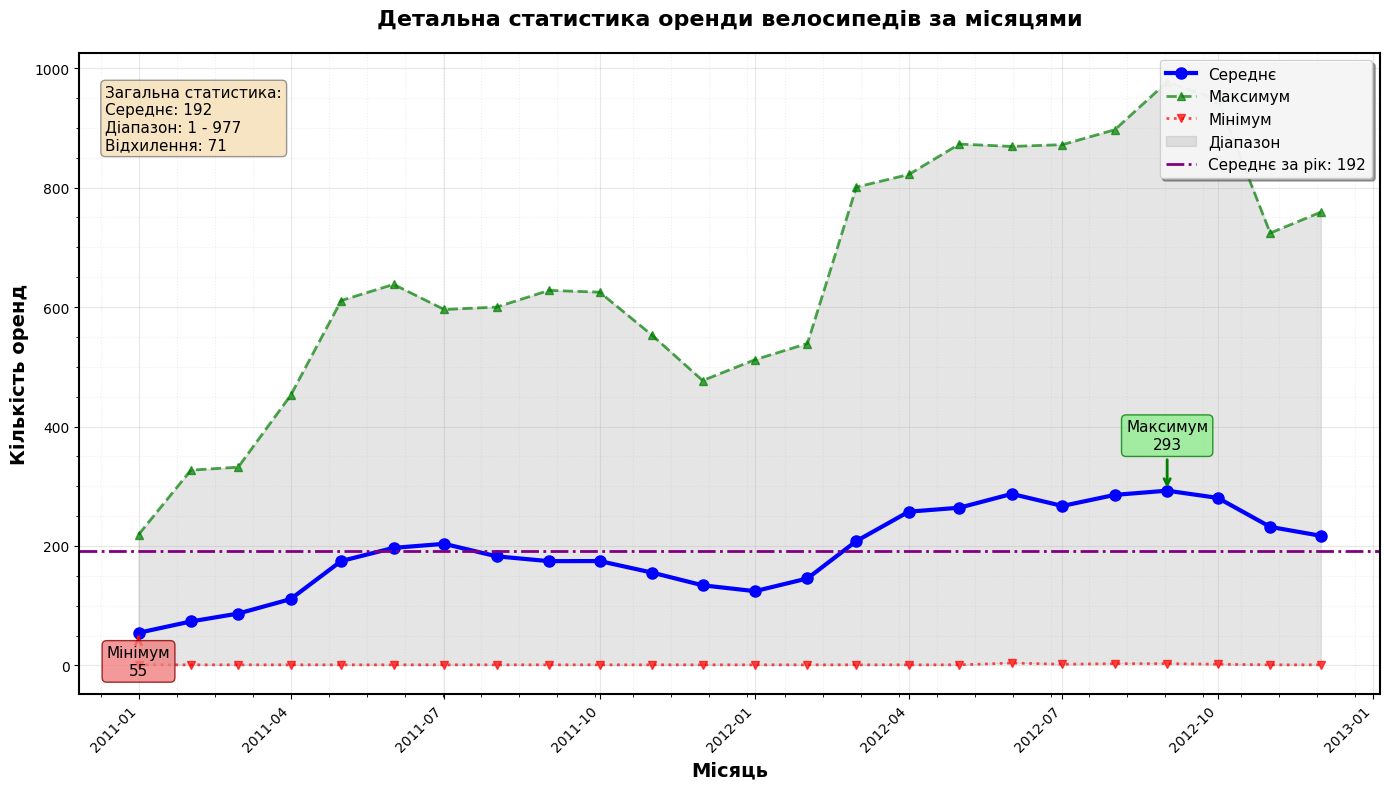

In [21]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

monthly_stats = df['count'].resample('MS').agg(['mean', 'max', 'min'])

fig, ax = plt.subplots(figsize=(14, 8))

ax.plot(
    monthly_stats.index,
    monthly_stats['mean'],
    'b-o',
    linewidth=3,
    markersize=8,
    label='Середнє'
)

ax.plot(
    monthly_stats.index,
    monthly_stats['max'],
    'g--^',
    linewidth=2,
    markersize=6,
    alpha=0.7,
    label='Максимум'
)

ax.plot(
    monthly_stats.index,
    monthly_stats['min'],
    'r:v',
    linewidth=2,
    markersize=6,
    alpha=0.7,
    label='Мінімум'
)

ax.fill_between(
    monthly_stats.index,
    monthly_stats['min'],
    monthly_stats['max'],
    color='gray',
    alpha=0.2,
    label='Діапазон'
)

max_idx = monthly_stats['mean'].idxmax()
max_val = monthly_stats['mean'].max()

ax.annotate(
    f'Максимум\n{max_val:.0f}',
    xy=(max_idx, max_val),
    xytext=(max_idx, max_val + 70),
    arrowprops=dict(
        arrowstyle='->',
        color='green',
        linewidth=2
    ),
    fontsize=11,
    horizontalalignment='center',
    bbox=dict(
        boxstyle='round,pad=0.3',
        facecolor='lightgreen',
        edgecolor='green',
        alpha=0.8
    )
)

min_idx = monthly_stats['mean'].idxmin()
min_val = monthly_stats['mean'].min()

ax.annotate(
    f'Мінімум\n{min_val:.0f}',
    xy=(min_idx, min_val),
    xytext=(min_idx, min_val - 70),
    arrowprops=dict(
        arrowstyle='->',
        color='red',
        linewidth=2
    ),
    fontsize=11,
    horizontalalignment='center',
    bbox=dict(
        boxstyle='round,pad=0.3',
        facecolor='lightcoral',
        edgecolor='darkred',
        alpha=0.8
    )
)

ax.set_title(
    'Детальна статистика оренди велосипедів за місяцями',
    fontsize=16,
    fontweight='bold',
    pad=20
)

ax.set_xlabel(
    'Місяць',
    fontsize=14,
    fontweight='bold'
)

ax.set_ylabel(
    'Кількість оренд',
    fontsize=14,
    fontweight='bold'
)

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter('%Y-%m')
)

ax.xaxis.set_minor_locator(
    mdates.MonthLocator()
)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    horizontalalignment='right'
)

ax.grid(
    True,
    which='major',
    linestyle='-',
    alpha=0.3
)

ax.grid(
    True,
    which='minor',
    linestyle=':',
    alpha=0.2
)

ax.minorticks_on()

overall_mean = df['count'].mean()

ax.axhline(
    y=overall_mean,
    color='purple',
    linestyle='-.',
    linewidth=2,
    label=f'Середнє за рік: {overall_mean:.0f}'
)

ax.legend(
    loc='upper right',
    fontsize=11,
    frameon=True,
    shadow=True,
    fancybox=True,
    framealpha=0.9
)

overall_min = monthly_stats['min'].min()
overall_max = monthly_stats['max'].max()
overall_std = monthly_stats['mean'].std()

textstr = (
    'Загальна статистика:\n'
    f'Середнє: {overall_mean:.0f}\n'
    f'Діапазон: {overall_min:.0f} - {overall_max:.0f}\n'
    f'Відхилення: {overall_std:.0f}'
)

props = dict(
    boxstyle='round',
    facecolor='wheat',
    edgecolor='gray',
    alpha=0.8
)

ax.text(
    0.02,
    0.95,
    textstr,
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment='top',
    bbox=props
)

for spine in ax.spines.values():
    spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()

Анотації допомагають одразу звернути увагу на найважливіші значення графіка. У нашому випадку вони позначають найвище та найнижче середні значення оренди й показують їхні числові значення. Завдяки цьому користувачеві не потрібно самостійно шукати екстремальні точки та приблизно визначати їх за шкалою.

Метод fill_between() використовується для заповнення простору між двома лініями. У нашому графіку він створює сіру напівпрозору область між мінімальною та максимальною кількістю оренд за кожен місяць. Така заливка наочно показує діапазон коливань: чим ширша сіра область, тим більшою є різниця між мінімальним і максимальним значеннями.

Текстовий блок показує ключові статистичні показники безпосередньо на графіку: загальне середнє, діапазон значень і відхилення. Це допомагає швидко зрозуміти загальний рівень оренди та масштаб коливань без додаткових розрахунків або перегляду таблиці. Текстовий блок доповнює візуалізацію точними числовими значеннями та робить графік більш інформативним.